# Step 6b — 50-Ohm matching network for the B3 design at 1.00 GHz (kit parts)

Design: `fiches_cst/resultats_V6/V6_parametres_B3_1.00GHz.json` — three 180 x 4 mm strips, spacings 45/65 mm,
el2 fed, el1 = 1 pF, el3 = 0.5 pF. Only the **lumped network at the gap** is designed here (balun and feed line: CST, V6c).

**Antenna one-port.** With the parasitic parts frozen, the antenna seen from the gap is $Z_A(f)$ and
$G_A(f) = 4\pi U(+y)/P_A$ ($\varphi$ polarisation, antenna conductor losses included). Both come from the MoM
frequency checks of the campaign (Z refilled at $f_0(1 + o)$, $o = -2 \dots +2\,\%$ by $0.5\,\%$), interpolated by
cubic splines (no extrapolation; leave-one-out error printed below). No new MoM fill is needed.

**Realised gain.** $G_r = G_A \, (1-|S_{11}|^2)\, \eta_{net}$, with $\eta_{net} = P_A / P_{in}$ the network efficiency
(component ESR included); exact two-port cascade (`solver.optim.matching`).

**Topologies** (elements listed from the 50-Ohm port to the gap):
`a` series C · `b_sp` shunt + series · `b_ps` series + shunt · `c_sp` shunt + series + series C(gap) ·
`c_ps` series + shunt + series C(gap). Every value combination of the kits (capacitors 0603 + 0402, inductors chip 0402
+ L402W) giving $|S_{11}(f_0)| \le -10$ dB is enumerated.

**Robust criterion.** Monte-Carlo over the part tolerances (uniform within $\pm$tol, 500 draws, seed 0, the same draws
for every candidate) $\times$ $f_0 \pm 0.5\,\%$ (5 frequencies): mean of $G_r$ (linear) and 10th percentile.

**Declared ranges, not data.** Capacitor ESR $\in \{0, 0.1, 0.3\}\,\Omega$ (ranking at 0.1 $\Omega$), ESL = 0
(sensitivity 0.5 and 1 nH); inductor $Q_L \in \{20, 40, 80\}$ (ranking at 40), $C_{par} = 0$ (sensitivity 0.1 pF).
The inductor Q and SRF are to be read on the Johanson datasheets.

In [1]:
%matplotlib inline
import csv, json, subprocess, sys
import datetime as dt
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'solver' / 'optim').is_dir())
sys.path.insert(0, str(ROOT))
from solver.optim.components import (CAPACITOR_KITS, INDUCTOR_KIT, PROVISIONAL_ESR_GRID, Q_L_RANGE, C_PAR_RANGE,
                                      ComponentModel, InductorModel)
from solver.optim import matching as mt

CST_DIR = Path(r'D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\fiches_cst\resultats_V6')
TAG = 'B3_1.00GHz'
design = json.loads((CST_DIR / f'V6_parametres_{TAG}.json').read_text(encoding='utf-8'))
with open(CST_DIR / f'V6_expected_{TAG}_freq.csv', newline='', encoding='utf-8') as fh:
    freq_rows = list(csv.DictReader(fh))
F0 = design['f0_GHz'] * 1e9
ant = mt.AntennaOnePort.from_freq_rows(freq_rows, F0)

ZA = complex(ant.zin(F0))
GA_DB = float(10 * np.log10(ant.gain(F0)))
Q_IN = design['expected']['Q_in']
Q_X = ZA.imag / ZA.real
zf = design['mesh_check']['Zin_ohm']
DZ_FINE = complex(*zf[1]) - complex(*zf[0])            # fine-mesh shift of Z_A at f0
gam = (ZA - 50) / (ZA + 50)
loo = ant.leave_one_out()
print(f'Z_A(f0) = {ZA.real:.2f} {ZA.imag:+.2f}j Ohm, G_A(f0) = {GA_DB:.2f} dBi, Q_in = {Q_IN:.1f}, X_A/R_A = {Q_X:.1f}')
print(f'no network: |S11| = {20 * np.log10(abs(gam)):.2f} dB, G_r = {GA_DB + 10 * np.log10(1 - abs(gam) ** 2):.2f} dBi '
      f"(campaign record: {design['expected']['G_r_50ohm_dBi']:.2f} dBi)")
print(f'MoM data: {len(freq_rows)} frequencies, {ant.f_min / 1e9:.3f} ... {ant.f_max / 1e9:.3f} GHz; '
      f"spline leave-one-out: max |dZ| = {max(r['dZ_ohm'] for r in loo):.4f} Ohm, "
      f"max |dG| = {max(abs(r['dG_dB']) for r in loo):.4f} dB")
print(f'fine-mesh shift of Z_A at f0: {DZ_FINE.real:+.2f} {DZ_FINE.imag:+.2f}j Ohm')

INK, INK_2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'lines.linewidth': 1.6, 'legend.frameon': False,
                     'font.size': 9, 'axes.titlesize': 10, 'figure.dpi': 110})

Z_A(f0) = 26.81 +298.82j Ohm, G_A(f0) = 9.76 dBi, Q_in = 61.8, X_A/R_A = 11.1
no network: |S11| = -0.25 dB, G_r = -2.73 dBi (campaign record: -2.73 dBi)
MoM data: 9 frequencies, 0.980 ... 1.020 GHz; spline leave-one-out: max |dZ| = 0.0028 Ohm, max |dG| = 0.0008 dB
fine-mesh shift of Z_A at f0: +0.57 +11.47j Ohm


## 1. Enumeration and ranking for each inductor Q in the declared range

In [2]:
CAP_REF = ComponentModel(esr=0.1, esl=0.0)          # ranking: middle of PROVISIONAL_ESR_GRID (range, not data)
Q_L_REF, C_PAR_REF = 40.0, 0.0                       # ranking: middle of Q_L_RANGE (range, not data)
N_MC, SEED = 500, 0
U = mt.tolerance_draws(N_MC, 3, SEED)
ind = lambda q=Q_L_REF, c=C_PAR_REF: InductorModel(q=q, c_par=c)

results = {}
for q in Q_L_RANGE:
    results[q] = mt.search(ant, CAP_REF, ind(q), n_mc=N_MC, seed=SEED, n_keep=None)
    r = results[q]
    print(f'Q_L = {q:g}: combinations with |S11(f0)| <= -10 dB: '
          + ', '.join(f"{t} {r.counts[t]}/{r.counts_total[t]}" for t in mt.TOPOLOGIES))

def line(i, e):
    b = e['band']
    return (f"{i:>2} {e['topology']:>5} {e['G_r_nominal_dBi']:6.2f} {e['G_r_mean_dBi']:6.2f} {e['G_r_p10_dBi']:6.2f} "
            f"{e['S11_dB']:6.1f} {b['bw_MHz']:6.1f} {e['network_loss_dB']:6.3f}  {e['description']}")
HEAD = (f"{'#':>2} {'topo':>5} {'G_r':>6} {'mean':>6} {'P10':>6} {'S11':>6} {'BW':>6} {'loss':>6}  elements (port -> gap)\n"
        f"{'':>2} {'':>5} {'dBi':>6} {'dBi':>6} {'dBi':>6} {'dB':>6} {'MHz':>6} {'dB':>6}")

Q_L = 20: combinations with |S11(f0)| <= -10 dB: a 0/29, b_sp 17/4356, b_ps 2/4356, c_sp 878/126324, c_ps 602/126324


Q_L = 40: combinations with |S11(f0)| <= -10 dB: a 0/29, b_sp 17/4356, b_ps 1/4356, c_sp 850/126324, c_ps 575/126324


Q_L = 80: combinations with |S11(f0)| <= -10 dB: a 0/29, b_sp 17/4356, b_ps 1/4356, c_sp 836/126324, c_ps 565/126324


In [3]:
ref = results[Q_L_REF]
top = []
for net, _, _ in ref.ranked[:10]:
    e = mt.evaluate_solution(net, ant, CAP_REF, ind(), U)
    e['net'] = net
    top.append(e)
print(f'Top 10, robust mean G_r (ESR_C = {CAP_REF.esr} Ohm, Q_L = {Q_L_REF:g}, ESL = C_par = 0)')
print(HEAD)
for i, e in enumerate(top, 1):
    print(line(i, e))
for q in Q_L_RANGE:
    ranked = results[q].ranked[:10]
    n_ind = sum(n.has_inductor for n, _, _ in ranked)
    best_ind = next(((n, m) for n, m, _ in results[q].ranked if n.has_inductor), None)
    print(f'Q_L = {q:g}: {n_ind} of the top 10 use an inductor; best with inductor: '
          f'{10 * np.log10(best_ind[1]):.2f} dBi mean ({best_ind[0].describe()})' if best_ind else '')

Top 10, robust mean G_r (ESR_C = 0.1 Ohm, Q_L = 40, ESL = C_par = 0)
 #  topo    G_r   mean    P10    S11     BW   loss  elements (port -> gap)
            dBi    dBi    dBi     dB    MHz     dB
 1  c_sp   9.61   9.34   8.71  -15.9   10.7  0.041  shunt 2.7 pF (C 0402/0603, +-4%) | series 1.2 pF (C 0402/0603, +-8%) | series 1.2 pF (C 0402/0603, +-8%)
 2  c_sp   9.55   9.32   8.74  -14.1   10.9  0.038  shunt 2.2 pF (C 0402/0603, +-5%) | series 1.2 pF (C 0402/0603, +-8%) | series 1.2 pF (C 0402/0603, +-8%)
 3  c_sp   9.61   9.32   8.61  -15.9   10.7  0.041  shunt 2.7 pF (C 0402/0603, +-4%) | series 1.5 pF (C 0402/0603, +-7%) | series 1 pF (C 0402/0603, +-10%)
 4  c_sp   9.55   9.31   8.66  -14.1   10.9  0.038  shunt 2.2 pF (C 0402/0603, +-5%) | series 1.5 pF (C 0402/0603, +-7%) | series 1 pF (C 0402/0603, +-10%)
 5  c_sp   9.65   9.28   8.57  -17.7   10.8  0.037  shunt 2.2 pF (C 0402/0603, +-5%) | series 0.8 pF (C 0402/0603, +-12%) | series 2.2 pF (C 0402/0603, +-5%)
 6  c_sp   9.71   9.2

## 2. Best solution per topology, capacitor-only solutions
Topology `a` (series C alone) never reaches $-10$ dB: its best value is shown for reference.

In [4]:
print(HEAD)
best_by_topo = {}
eparts = mt.electrical_parts(list(CAPACITOR_KITS) + list(INDUCTOR_KIT))
caps = [p for p in eparts if not p.is_inductor]
a_nets = [mt.Network('a', (c,)) for c in caps]
a_best = max(a_nets, key=lambda n: float(mt.network_response(n, F0, ant, CAP_REF, ind())['G_r']))
best_by_topo['a'] = mt.evaluate_solution(a_best, ant, CAP_REF, ind(), U) | {'net': a_best}
for t in list(mt.TOPOLOGIES)[1:]:
    for with_l in (False, True):
        cand = [n for n, _, _ in ref.ranked if n.topology == t and n.has_inductor == with_l]
        if cand:
            best_by_topo[(t, with_l)] = mt.evaluate_solution(cand[0], ant, CAP_REF, ind(), U) | {'net': cand[0]}
for k, e in best_by_topo.items():
    print(line(k if isinstance(k, str) else f"{'L' if k[1] else 'C'}", e))
cap_only = [n for n, _, _ in ref.ranked if not n.has_inductor]
print(f'\ncapacitor-only networks with |S11(f0)| <= -10 dB (after merging equivalents): {len(cap_only)}'
      f" (top-ranked overall: {'capacitor-only' if not ref.ranked[0][0].has_inductor else 'with inductor'})")

 #  topo    G_r   mean    P10    S11     BW   loss  elements (port -> gap)
            dBi    dBi    dBi     dB    MHz     dB
 a     a   9.06   8.37   6.01   -8.4    0.0  0.016  series 0.5 pF (C 0402/0603, +-20%)
 L  b_sp   9.46   8.53   6.86  -12.6    9.0  0.051  shunt 20 nH (L 0402, +-5%) | series 0.5 pF (C 0402/0603, +-20%)
 L  b_ps   8.52   7.81   5.86  -13.8   11.3  1.056  series 56 nH (L 0402, +-5%) | shunt 1 pF (C 0402/0603, +-10%)
 C  c_sp   9.61   9.34   8.71  -15.9   10.7  0.041  shunt 2.7 pF (C 0402/0603, +-4%) | series 1.2 pF (C 0402/0603, +-8%) | series 1.2 pF (C 0402/0603, +-8%)
 L  c_sp   9.58   9.26   8.66  -17.0   10.8  0.091  shunt 12 nH (L 0402, +-5%) | series 1 pF (C 0402/0603, +-10%) | series 1 pF (C 0402/0603, +-10%)
 C  c_ps   9.58   9.23   8.44  -14.6   10.8  0.027  series 1.5 pF (C 0402/0603, +-7%) | shunt 0.3 pF (C 0402/0603, +-33%) | series 0.8 pF (C 0402/0603, +-12%)
 L  c_ps   9.46   8.44   6.70  -12.8    9.1  0.063  series 1 nH (L 0402, +-20%) | shunt 27 n

## 3. Network loss vs the Q of the load and of the components (order of magnitude)

The element that cancels the antenna reactance $X_A$ carries $|X| \approx X_A$ in series with $R_A$. With a component
quality factor $Q_c = |X|/R_{loss}$, $R_{loss} = R_A\,Q_X/Q_c$ ($Q_X = X_A/R_A$), so the lost fraction is
$1/(1+Q_c/Q_X) \approx Q_X/Q_c$. For a small antenna far from resonance $Q_X \approx Q_{in}$, hence the rule
**loss $\approx Q_{in}/Q_c$** — an approximation (it ignores the transformation section and assumes $Q_{in} \ll Q_c$).
Here $Q_{in} = 62$ but $Q_X = 11$: the superdirective array stores more energy than its reactance at $f_0$ shows, so the
rule overestimates the loss at $f_0$, while $Q_{in}$ still sets the band: $\mathrm{FBW}_{-10\,dB} \approx (S-1)/(Q_{in}\sqrt{S})$, $S = 1.925$.
Inductors only appear in the transformation section, where the loaded Q is $\sqrt{50/R_A - 1} \approx 0.93$.

In [5]:
best = top[0]
net = best['net']
w0 = 2 * np.pi * F0
print(f"retained network: {net.describe()}")
x_ser = sum(-1 / (w0 * p.value) for pos, p in zip(net.positions, net.parts) if pos == 'series' and not p.is_inductor)
r_ser = sum(CAP_REF.esr for pos, p in zip(net.positions, net.parts) if pos == 'series')
q_c = abs(x_ser) / r_ser
print(f'series capacitors: X = {x_ser:.1f} Ohm, ESR = {r_ser:.2f} Ohm -> Q_c = {q_c:.0f}')
print(f'  rule Q_in/Q_c = {Q_IN / q_c:.3%} ({-10 * np.log10(1 - Q_IN / q_c):.3f} dB); '
      f'Q_X/Q_c = {Q_X / q_c:.3%} ({10 * np.log10(1 + Q_X / q_c):.3f} dB); '
      f"exact network loss = {best['network_loss_dB']:.3f} dB (incl. the shunt part)")
S = 1.925
print(f"band rule (S-1)/(Q_in sqrt S) = {100 * (S - 1) / (Q_IN * np.sqrt(S)):.2f} % of f0 "
      f"vs computed {best['band']['bw_pct']:.2f} %")
for q in Q_L_RANGE:
    print(f'if an inductor of Q = {q:g} had to carry |X| = {abs(x_ser):.0f} Ohm: loss ~ {10 * np.log10(1 + Q_X / q):.2f} dB '
          f'(rule Q_in/Q_L = {Q_IN / q:.2f}, outside its validity); '
          f'in the transformation section (Q ~ 0.93): ~ {10 * np.log10(1 + 0.93 / q):.3f} dB')

retained network: shunt 2.7 pF (C 0402/0603, +-4%) | series 1.2 pF (C 0402/0603, +-8%) | series 1.2 pF (C 0402/0603, +-8%)
series capacitors: X = -265.3 Ohm, ESR = 0.20 Ohm -> Q_c = 1326
  rule Q_in/Q_c = 4.663% (0.207 dB); Q_X/Q_c = 0.840% (0.036 dB); exact network loss = 0.041 dB (incl. the shunt part)
band rule (S-1)/(Q_in sqrt S) = 1.08 % of f0 vs computed 1.07 %
if an inductor of Q = 20 had to carry |X| = 265 Ohm: loss ~ 1.92 dB (rule Q_in/Q_L = 3.09, outside its validity); in the transformation section (Q ~ 0.93): ~ 0.197 dB
if an inductor of Q = 40 had to carry |X| = 265 Ohm: loss ~ 1.07 dB (rule Q_in/Q_L = 1.55, outside its validity); in the transformation section (Q ~ 0.93): ~ 0.100 dB
if an inductor of Q = 80 had to carry |X| = 265 Ohm: loss ~ 0.57 dB (rule Q_in/Q_L = 0.77, outside its validity); in the transformation section (Q ~ 0.93): ~ 0.050 dB


## 4. Sensitivity of the three best solutions and of the best one with an inductor
Rows: capacitor ESR, inductor $Q_L$, capacitor ESL, inductor $C_{par}$ (all declared ranges), and the fine-mesh shift of
$Z_A$ (applied at every frequency).

In [6]:
sens_nets = [e['net'] for e in top[:3]]
with_l = next((n for n, _, _ in ref.ranked if n.has_inductor), None)
if with_l is not None and with_l not in sens_nets:
    sens_nets.append(with_l)
cases = ([(f'ESR_C = {r:g} Ohm', ComponentModel(r, 0.0), ind(), ant) for r in PROVISIONAL_ESR_GRID]
         + [(f'Q_L = {q:g}', CAP_REF, ind(q), ant) for q in Q_L_RANGE]
         + [(f'ESL_C = {l * 1e9:g} nH', ComponentModel(CAP_REF.esr, l), ind(), ant) for l in (0.5e-9, 1.0e-9)]
         + [(f'C_par = {c * 1e12:g} pF', CAP_REF, ind(c=c), ant) for c in C_PAR_RANGE if c > 0]
         + [('Z_A + fine-mesh shift', CAP_REF, ind(), ant.shifted(DZ_FINE))])
sensitivity = []
for k, n in enumerate(sens_nets):
    print(f"\n[{k + 1 if k < 3 else 'L'}] {n.describe()}")
    print(f"   {'case':<24} {'G_r':>6} {'mean':>6} {'P10':>6} {'S11':>6} {'BW':>6} {'loss':>6}")
    rows = []
    for name, cm, lm, a in cases:
        e = mt.evaluate_solution(n, a, cm, lm, U)
        rows.append(dict(case=name, **{k2: e[k2] for k2 in ('G_r_nominal_dBi', 'G_r_mean_dBi', 'G_r_p10_dBi',
                                                             'S11_dB', 'network_loss_dB')},
                         bw_MHz=e['band']['bw_MHz']))
        print(f"   {name:<24} {e['G_r_nominal_dBi']:6.2f} {e['G_r_mean_dBi']:6.2f} {e['G_r_p10_dBi']:6.2f} "
              f"{e['S11_dB']:6.1f} {e['band']['bw_MHz']:6.1f} {e['network_loss_dB']:6.3f}")
    sensitivity.append(dict(network=n.describe(), rows=rows))


[1] shunt 2.7 pF (C 0402/0603, +-4%) | series 1.2 pF (C 0402/0603, +-8%) | series 1.2 pF (C 0402/0603, +-8%)
   case                        G_r   mean    P10    S11     BW   loss
   ESR_C = 0 Ohm              9.65   9.38   8.74  -15.8   10.6 -0.000
   ESR_C = 0.1 Ohm            9.61   9.34   8.71  -15.9   10.7  0.041
   ESR_C = 0.3 Ohm            9.53   9.27   8.65  -16.2   10.8  0.122
   Q_L = 20                   9.61   9.34   8.71  -15.9   10.7  0.041
   Q_L = 40                   9.61   9.34   8.71  -15.9   10.7  0.041
   Q_L = 80                   9.61   9.34   8.71  -15.9   10.7  0.041
   ESL_C = 0.5 nH             9.41   9.18   8.26  -11.6   10.7  0.044
   ESL_C = 1 nH               9.08   8.93   7.72   -8.7    0.0  0.049
   C_par = 0.1 pF             9.61   9.34   8.71  -15.9   10.7  0.041
   Z_A + fine-mesh shift      9.19   9.03   7.97   -9.4    0.0  0.044

[2] shunt 2.2 pF (C 0402/0603, +-5%) | series 1.2 pF (C 0402/0603, +-8%) | series 1.2 pF (C 0402/0603, +-8%)
   case   

   ESL_C = 0.5 nH             9.41   9.17   8.16  -11.6   10.7  0.044
   ESL_C = 1 nH               9.08   8.92   7.61   -8.7    0.0  0.049
   C_par = 0.1 pF             9.61   9.32   8.61  -15.9   10.7  0.041
   Z_A + fine-mesh shift      9.19   9.02   7.87   -9.4    0.0  0.044

[L] shunt 12 nH (L 0402, +-5%) | series 1 pF (C 0402/0603, +-10%) | series 1 pF (C 0402/0603, +-10%)
   case                        G_r   mean    P10    S11     BW   loss
   ESR_C = 0 Ohm              9.61   9.28   8.68  -16.8   10.7  0.059
   ESR_C = 0.1 Ohm            9.58   9.26   8.66  -17.0   10.8  0.091
   ESR_C = 0.3 Ohm            9.53   9.21   8.61  -17.4   11.0  0.155
   Q_L = 20                   9.52   9.19   8.59  -16.7   11.1  0.149
   Q_L = 40                   9.58   9.26   8.66  -17.0   10.8  0.091
   Q_L = 80                   9.61   9.29   8.69  -17.1   10.7  0.062
   ESL_C = 0.5 nH             9.49   9.20   8.50  -13.8   10.9  0.080
   ESL_C = 1 nH               9.32   9.08   8.19  -10.9   

In [7]:
# where does the robust loss of #1 come from? tolerances alone (f0 only) vs frequency alone (nominal values)
n1 = top[0]['net']
pos, is_ind = n1.positions, np.array([[p.is_inductor for p in n1.parts]])
nom = np.array([[p.value for p in n1.parts]]); tol = np.array([[p.tol_abs for p in n1.parts]])
m_tol, p_tol = mt.robust_stats(pos, is_ind, nom, tol, F0, ant, CAP_REF, ind(), U, f_offsets=(0.0,))
m_f, p_f = mt.robust_stats(pos, is_ind, nom, tol, F0, ant, CAP_REF, ind(), np.zeros_like(U))
db = lambda x: 10 * np.log10(float(x[0]))
print(f"#1 nominal {top[0]['G_r_nominal_dBi']:.2f} dBi | tolerances only: mean {db(m_tol):.2f}, P10 {db(p_tol):.2f} | "
      f"f0 +- 0.5 % only: mean {db(m_f):.2f}, P10 {db(p_f):.2f} | both: mean {top[0]['G_r_mean_dBi']:.2f}, "
      f"P10 {top[0]['G_r_p10_dBi']:.2f} dBi")

#1 nominal 9.61 dBi | tolerances only: mean 9.53, P10 9.22 | f0 +- 0.5 % only: mean 9.41, P10 8.80 | both: mean 9.34, P10 8.71 dBi


## 5. Ranking redone with a capacitor ESL (the most sensitive parameter above)

In [8]:
esl_rankings = {}
for esl in (0.5e-9, 1.0e-9):
    cm = ComponentModel(CAP_REF.esr, esl)
    r = mt.search(ant, cm, ind(), n_mc=N_MC, seed=SEED, n_keep=5)
    print(f'\nESL_C = {esl * 1e9:g} nH (ESR_C = {CAP_REF.esr} Ohm, Q_L = {Q_L_REF:g}): combinations <= -10 dB: '
          + ', '.join(f'{t} {r.counts[t]}' for t in mt.TOPOLOGIES))
    print(HEAD)
    rows = []
    for i, (n, _, _) in enumerate(r.ranked, 1):
        e = mt.evaluate_solution(n, ant, cm, ind(), U)
        print(line(i, e))
        rows.append(dict(rank=i, description=e['description'], elements_port_to_gap=mt.part_records(n),
                         **{k: e[k] for k in ('G_r_nominal_dBi', 'G_r_mean_dBi', 'G_r_p10_dBi', 'S11_dB', 'network_loss_dB')}))
    esl_rankings[f'{esl * 1e9:g} nH'] = rows


ESL_C = 0.5 nH (ESR_C = 0.1 Ohm, Q_L = 40): combinations <= -10 dB: a 0, b_sp 19, b_ps 1, c_sp 910, c_ps 549
 #  topo    G_r   mean    P10    S11     BW   loss  elements (port -> gap)
            dBi    dBi    dBi     dB    MHz     dB
 1  c_sp   9.54   9.28   8.67  -13.8   10.3  0.034  shunt 1.8 pF (C 0402/0603, +-6%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)
 2  c_sp   9.55   9.28   8.51  -14.1   10.4  0.035  shunt 2.2 pF (C 0402/0603, +-5%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)
 3  c_ps   9.73   9.27   8.45  -29.1    9.8  0.026  series 0.8 pF (C 0402/0603, +-12%) | shunt 0.3 pF (C 0402/0603, +-33%) | series 1 pF (C 0402/0603, +-10%)
 4  c_sp   9.51   9.27   8.76  -13.2    9.8  0.034  shunt 1.5 pF (C 0402/0603, +-7%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)
 5  c_sp   9.64   9.27   8.49  -17.1   10.5  0.036  shunt 2.2 pF (C 0402/0603, +-5%) | series 0.8 pF (C 0402/0603, +-12%) | series 1.8 pF 


ESL_C = 1 nH (ESR_C = 0.1 Ohm, Q_L = 40): combinations <= -10 dB: a 0, b_sp 18, b_ps 1, c_sp 933, c_ps 529
 #  topo    G_r   mean    P10    S11     BW   loss  elements (port -> gap)
            dBi    dBi    dBi     dB    MHz     dB
 1  c_sp   9.67   9.36   8.77  -19.1   10.5  0.036  shunt 2.2 pF (C 0402/0603, +-5%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)
 2  c_sp   9.62   9.34   8.85  -16.2   10.4  0.035  shunt 1.8 pF (C 0402/0603, +-6%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)
 3  c_sp   9.68   9.31   8.59  -19.9    9.7  0.039  shunt 2.7 pF (C 0402/0603, +-4%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)
 4  c_sp   9.56   9.31   8.86  -14.3    9.9  0.034  shunt 1.5 pF (C 0402/0603, +-7%) | series 1 pF (C 0402/0603, +-10%) | series 1.2 pF (C 0402/0603, +-8%)
 5  c_sp   9.70   9.30   8.58  -21.8   10.6  0.037  shunt 2.2 pF (C 0402/0603, +-5%) | series 0.8 pF (C 0402/0603, +-12%) | series 1.8 pF (C 0

## 6. $|S_{11}|(f)$ and $G_r(f)$ of the three best solutions
Networks that are nominally identical (e.g. 1.2 + 1.2 pF and 1.5 + 1 pF in series = 0.6 pF) differ only by their
tolerances: the figure shows the three best **nominally distinct** networks.

saved D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\fiches_cst\resultats_V6\V6_adaptation_B3_1.00GHz.png


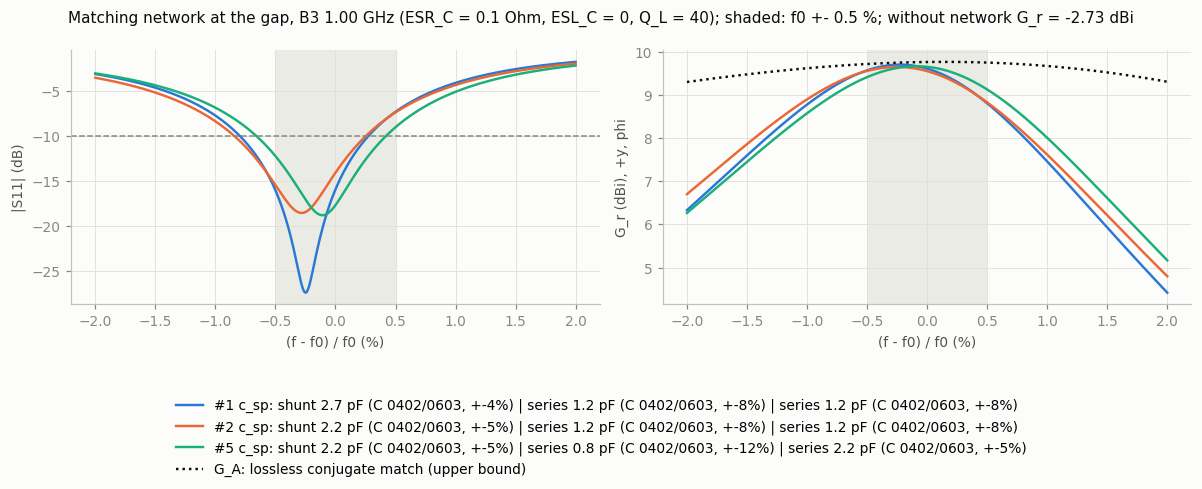

In [9]:
doc_nonet = GA_DB + 10 * np.log10(1 - abs(gam) ** 2)
f = np.linspace(ant.f_min, ant.f_max, 401)
off = 100 * (f / F0 - 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
curves, shown, sig_seen = [], [], set()
for e in top:
    sig = (round(e['S11_dB'], 2), round(e['G_r_nominal_dBi'], 3))
    if sig not in sig_seen:
        sig_seen.add(sig)
        shown.append((top.index(e), e))
    if len(shown) == 3:
        break
for i, (rank0, e) in enumerate(shown):
    r = mt.network_response(e['net'], f, ant, CAP_REF, ind())
    s = 20 * np.log10(np.abs(r['s11']))
    g = 10 * np.log10(r['G_r'])
    curves.append(dict(rank=rank0 + 1, description=e['description'], f_GHz=(f / 1e9).tolist(),
                       S11_dB=s.tolist(), G_r_dBi=g.tolist()))
    lab = f"#{rank0 + 1} {e['topology']}: {e['description']}"
    axes[0].plot(off, s, color=SERIES[i], label=lab)
    axes[1].plot(off, g, color=SERIES[i], label=lab)
axes[1].plot(off, 10 * np.log10(ant.gain(f)), color=INK, ls=':', label='G_A: lossless conjugate match (upper bound)')
axes[0].axhline(-10, color=MUTED, ls='--', lw=1)
for ax in axes:
    ax.axvspan(-0.5, 0.5, color=GRID, alpha=0.6, lw=0)
    ax.set_xlabel('(f - f0) / f0 (%)')
axes[0].set_ylabel('|S11| (dB)'); axes[1].set_ylabel('G_r (dBi), +y, phi')
fig.suptitle(f'Matching network at the gap, B3 1.00 GHz (ESR_C = {CAP_REF.esr} Ohm, ESL_C = 0, Q_L = {Q_L_REF:g}); '
             f"shaded: f0 +- 0.5 %; without network G_r = {doc_nonet:.2f} dBi", fontsize=10, color=INK)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=1)
fig.tight_layout(rect=(0, 0.25, 1, 1))
FIG = CST_DIR / f'V6_adaptation_{TAG}.png'
fig.savefig(FIG, dpi=150)
print('saved', FIG)
plt.show()

## 7. Export `V6_adaptation_B3_1.00GHz.json`

In [10]:
def git_info():
    run = lambda *a: subprocess.run(['git', *a], cwd=ROOT, capture_output=True, text=True).stdout.strip()
    return dict(commit=run('rev-parse', 'HEAD'), branch=run('rev-parse', '--abbrev-ref', 'HEAD'),
                dirty=bool(run('status', '--porcelain')))

def sol_record(e, rank):
    n = e['net']
    return dict(rank=rank, topology=n.topology, topology_text=mt.TOPOLOGY_TEXT[n.topology],
                elements_port_to_gap=mt.part_records(n), has_inductor=n.has_inductor,
                expected={k: e[k] for k in ('G_r_nominal_dBi', 'G_r_mean_dBi', 'G_r_p10_dBi', 'S11_dB',
                                            'mismatch_dB', 'network_loss_dB', 'eta_net', 'z_port_ohm', 'band')})

doc = dict(
    campaign=f'adaptation_{TAG}', generated=dt.datetime.now().isoformat(timespec='seconds'), git=git_info(),
    design=dict(file=f'V6_parametres_{TAG}.json', f0_GHz=F0 / 1e9, fed_port='el2 (gap at x = 0)',
                Z_A_f0_ohm=[ZA.real, ZA.imag], G_A_f0_dBi=GA_DB, Q_in=Q_IN, X_over_R=Q_X,
                G_r_without_network_dBi=GA_DB + 10 * np.log10(1 - abs(gam) ** 2)),
    antenna_data=dict(source=f'V6_expected_{TAG}_freq.csv (MoM, parasitic parts frozen, alpha_cal, ESR = 0)',
                      f_range_GHz=[ant.f_min / 1e9, ant.f_max / 1e9], n_freq=len(freq_rows),
                      interpolation='cubic spline in f/f0 - 1 (Re Z, Im Z, G in dB), no extrapolation',
                      leave_one_out_max_dZ_ohm=max(r['dZ_ohm'] for r in loo),
                      leave_one_out_max_dG_dB=max(abs(r['dG_dB']) for r in loo),
                      fine_mesh_shift_ohm=[DZ_FINE.real, DZ_FINE.imag]),
    reference_plane='50-Ohm port at the gap of el2 (balun + feed line designed in CST, V6c); elements listed port -> gap',
    models=dict(
        capacitor=dict(model='R_ESR + j w L_ESL + 1/(j w C)', esr_ohm_ranking=CAP_REF.esr,
                       esr_ohm_range=list(PROVISIONAL_ESR_GRID), esl_nH_ranking=0.0, esl_nH_sensitivity=[0.5, 1.0],
                       status='PROVISIONAL RANGE, NOT DATA (Johanson S-Series curves to be read)'),
        inductor=dict(model='(w L/Q + j w L) parallel C_par', q_ranking=Q_L_REF, q_range=list(Q_L_RANGE),
                      c_par_pF_ranking=0.0, c_par_pF_sensitivity=[c * 1e12 for c in C_PAR_RANGE if c > 0],
                      status='RANGE, NOT DATA (Q and SRF at 1 GHz to be read on the Johanson chip-0402 / L402W datasheets)')),
    robust=dict(distribution='uniform within +- tolerance, independent', n_mc=N_MC, seed=SEED,
                f_offsets_pct=[100 * o for o in mt.F_OFFSETS_ROBUST], statistic='mean (linear) and 10th percentile of G_r'),
    combinations_s11_le_m10dB={f'Q_L={q:g}': results[q].counts for q in Q_L_RANGE},
    combinations_total=ref.counts_total,
    solutions=[sol_record(e, i + 1) for i, e in enumerate(top)],
    best_per_topology=[dict(key=str(k), **sol_record(e, None)) for k, e in best_by_topo.items()],
    capacitor_only_possible=bool(cap_only), recommended_rank=1,
    sensitivity=sensitivity, esl_aware_rankings=esl_rankings,
    robust_decomposition_rank1=dict(tolerances_only_mean_dBi=db(m_tol), tolerances_only_p10_dBi=db(p_tol),
                                    frequency_only_mean_dBi=db(m_f), frequency_only_p10_dBi=db(p_f)),
    expected_curves_top3_distinct=curves, figure=FIG.name)
path = CST_DIR / f'V6_adaptation_{TAG}.json'
path.write_text(json.dumps(doc, indent=1, default=float), encoding='utf-8')
print('exported', path)

exported D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\fiches_cst\resultats_V6\V6_adaptation_B3_1.00GHz.json
